In [1]:
# laden der Packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings("ignore")

# Wahrscheinlichkeitsrechnung & Zufallsvariablen


### Ziele der Übung

- Grundbegriffe
- Wahrscheinlichkeiten und Bedingte Wahrscheinlichkeiten
- Formel von Bayes
- Zufallsvariablen

## Aufgabe 1

Gegeben sei ein sechsseitiger Würfel.
- $A$ die Menge der ungeraden Augenzahlen, 
- $B$ die Menge der geraden Augenzahlen, 
- $C = \{1,2,3\}$.

Bestimme folgende Mengen: 
- $A$ 
- $\overline{A}$ 
- $B$ 
- $\overline{B}$  
- $C$ 
- $\overline{C}$  
- $\overline{A \cap C}$
- $A \setminus B$
- $A \setminus \overline{C}$
- $A\cup (B\cap C)$
- $A\cap (B\cap ( C \setminus \overline{B}))$ 

**Lösung**

- $A = \{1,3,5\}$ 
- $\overline{A} = \{2,4,6\}$ 
- $B = \{2,4,6\}$ 
- $\overline{B} = \{1,3,5\}$  
- $C = \{1,2,3\}$ 
- $\overline{C} = \{4,5,6\}$  
- $\overline{A \cap C} = \overline{\{1,3\}} = \{2,4,5,6\}$
- $A \setminus B  = \{1,3,5\}$
- $A \setminus \overline{C}  = \{1,3\}$
- $A\cup (B\cap C) = \{1,2, 3, 5\}$
- $A\cap (B\cap ( C \setminus \overline{B})) = \{\}$ 

## Aufgabe 2

**Spam-Filter:** Ein E-Mail-Programm soll entscheiden, ob eine eingegangene Nachricht Spam ist. Man weiß aus Erfahrung, dass 20\% SPAM Nachrichten sind. Die Wahrscheinlichkeit, dass eine SPAM Nachricht das Wort "Gewinn" enthält, ist 19\%. Die Wahrscheinlichkeit, dass eine nicht-SPAM Nachricht dieses Wort enthält, beträgt nur 1\%. 
- Zeichne einen Wahrscheinlichkeitsbaum. 
- Wie groß ist die Wahrscheinlichkeit, dass eine neue Nachricht mit dem Wort "Gewinn" eine SPAM Nachricht ist? 
- Wie groß ist die Wahrscheinlichkeit, dass eine neue SPAM-Nachricht das Wort "Gewinn" enthält?
- Wie groß ist die Wahrscheinlichkeit, dass eine neue Nachricht das Wort "Gewinn" enthält?

**Lösung**

Zeichne einen Wahrscheinlichkeitsbaum. 

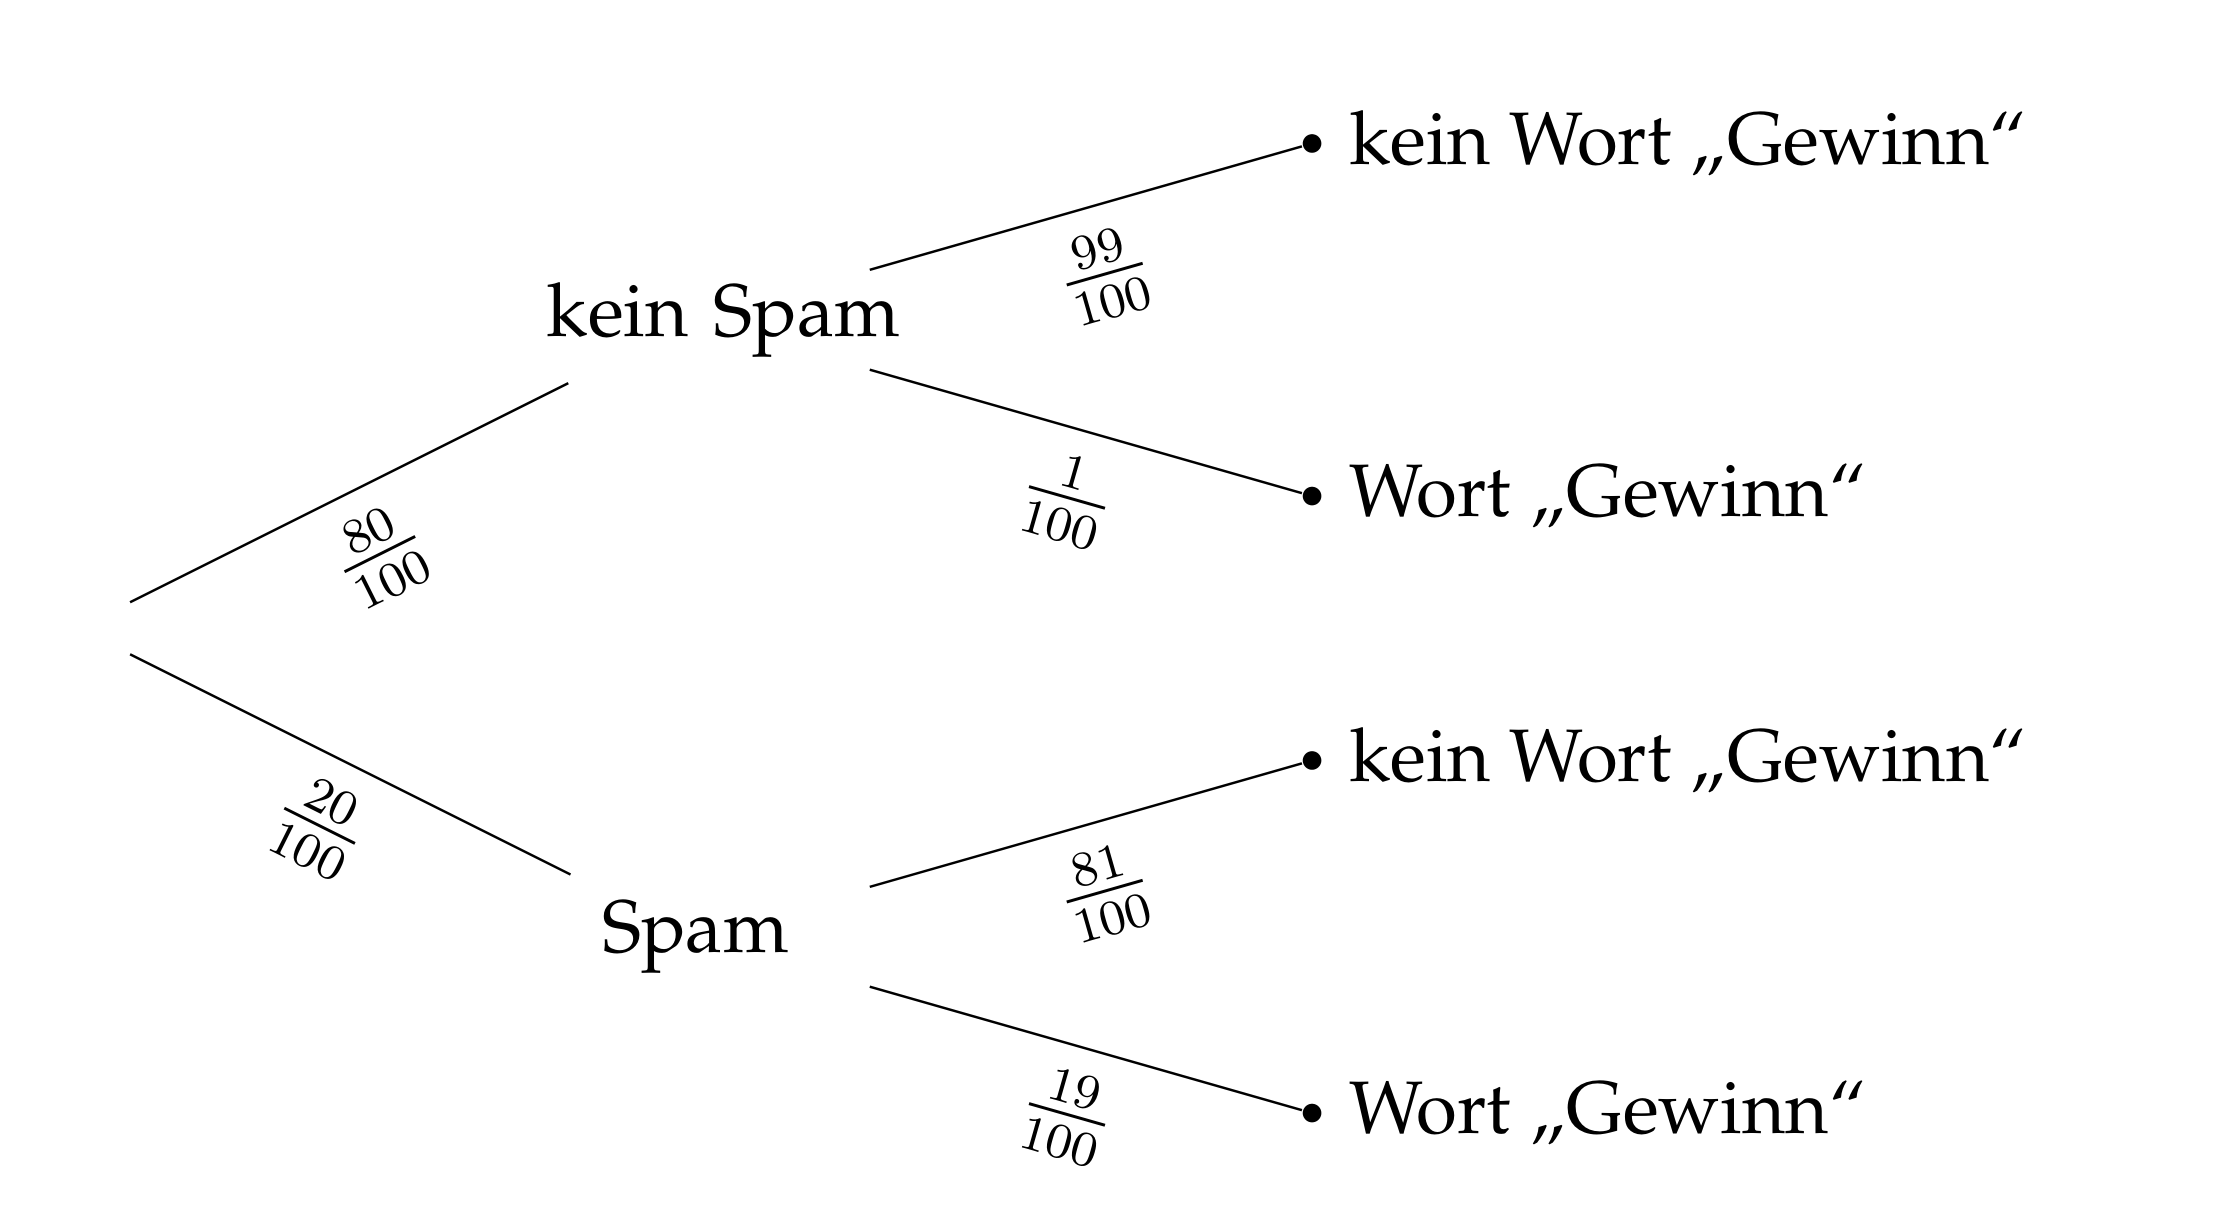

- Wie groß ist die Wahrscheinlichkeit, dass eine neue Nachricht mit dem Wort "Gewinn" eine SPAM Nachricht ist?

**Satz von Bayes:** 

$P(\text{Spam} | \text{"Gewinn"}) = \frac{ \frac{20}{100}\cdot \frac{19}{100} }{\frac{20}{100}\cdot \frac{19}{100} + \frac{80}{100}\cdot \frac{1}{100}} = 82.6\%$

In [3]:
(0.2*0.19) / ( 0.2*0.19 + 0.8*0.01) * 100

82.6086956521739

- Wie groß ist die Wahrscheinlichkeit, dass eine neue SPAM-Nachricht das Wort "Gewinn" enthält?

Aus der Angabe erkennt man direkt, dass es 19\% sind. 

- Wie groß ist die Wahrscheinlichkeit, dass eine neue Nachricht das Wort "Gewinn" enthält?

Gefragt ist die totale Wahrscheinlichkeit:

$P(\text{"Gewinn"}) = P(\text{Spam}) \cdot P(\text{"Gewinn"} | \text{Spam}) + P(\text{kein Spam}) \cdot P( \text{"Gewinn"} | \text{kein Spam}) = \frac{20}{100}\cdot \frac{19}{100} + \frac{80}{100}\cdot \frac{1}{100} = 4.6\%$

In [4]:
( 0.2*0.19 + 0.8*0.01) * 100

4.6000000000000005

## Aufgabe 3
Theoretische Verteilung: Du würfelst zweimal und bist an der Zufallsvariable $X = $ Augensumme interessiert.
- Stelle in einer Tabelle absolute und relative Häufigkeiten dar. 
- Stelle die Wahrscheinlichkeitsverteilung von $X$ mit einem Histogramm dar. 
- Stelle die kumulative Verteilungsfunktion von $X$ dar.  
- Bestimme $P(X = 7)$, $P(X \leq 7)$, $P(X > 7 )$ und $P( 3\leq X < 7 )$.

**Lösung**

In [2]:
x = np.arange(2,13)
absH = [1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1] 
relH = np.divide(absH, 36)

dataWürfel = pd.DataFrame(data = {
    "Summe Augenzahl": x,
    "Abs. Häufigkeiten": absH,
    "Rel. Häufigkeiten": relH, 
    "CDF": np.cumsum(relH)
})

dataWürfel

,Summe Augenzahl,Abs. Häufigkeiten,Rel. Häufigkeiten,CDF
0,2,1,0.027778,0.027778
1,3,2,0.055556,0.083333
2,4,3,0.083333,0.166667
3,5,4,0.111111,0.277778
4,6,5,0.138889,0.416667
5,7,6,0.166667,0.583333
6,8,5,0.138889,0.722222
7,9,4,0.111111,0.833333
8,10,3,0.083333,0.916667
9,11,2,0.055556,0.972222


In [6]:
round(sum(dataWürfel['Summe Augenzahl']*dataWürfel['Rel. Häufigkeiten']))

7

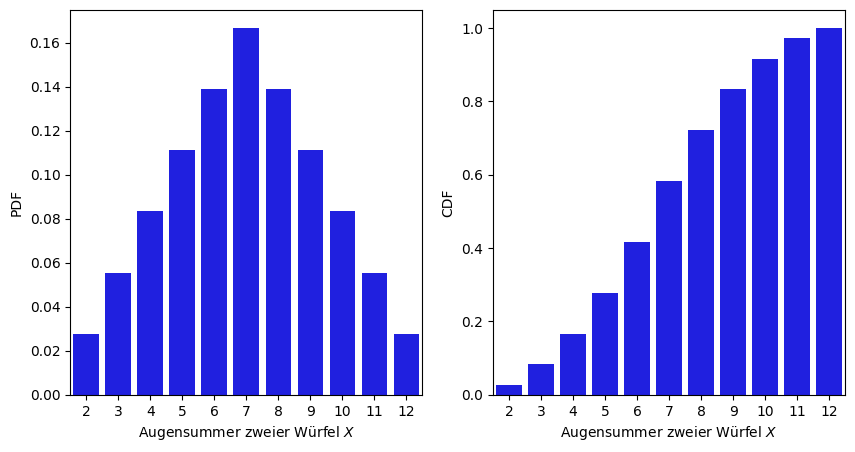

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.barplot(data=dataWürfel, x="Summe Augenzahl", y="Rel. Häufigkeiten", color="b", ax=axes[0]) # PDF
axes[0].set_xlabel('Augensummer zweier Würfel $X$')
axes[0].set_ylabel('PDF')

sns.barplot(data=dataWürfel, x="Summe Augenzahl", y="CDF", color="b", ax=axes[1]) # CDF
axes[1].set_xlabel('Augensummer zweier Würfel $X$')
axes[1].set_ylabel('CDF');

Bestimme $P(X = 7)$, $P(X \leq 7)$, $P(X > 7 )$ und $P( 3\leq X < 7 )$:

In [7]:
dataWürfel["Rel. Häufigkeiten"].values[dataWürfel["Summe Augenzahl"].values == 7][0]

0.16666666666666666

In [8]:
dataWürfel["CDF"].values[dataWürfel["Summe Augenzahl"].values == 7][0]

0.5833333333333334

In [9]:
1 - dataWürfel["CDF"].values[dataWürfel["Summe Augenzahl"].values == 7][0]

0.41666666666666663

In [10]:
dataWürfel["CDF"].values[dataWürfel["Summe Augenzahl"].values == 6][0] - dataWürfel["CDF"].values[dataWürfel["Summe Augenzahl"].values == 2][0]

0.3888888888888889

## Aufgabe 4
Empirische Verteilung: Du würfelst $n = 30$ mal und bist an der Zufallsvariable $X = $ Augensumme interessiert.
- Stelle in einer Tabelle absolute und relative Häufigkeiten dar. 
- Stelle die Wahrscheinlichkeitsverteilung von $X$ mit einem Histogramm dar. 
- Stelle die kumulative Verteilungsfunktion von $X$ dar.  
- Bestimme $P(X = 7)$, $P(X \leq 7)$, $P(X > 7 )$ und $P( 3\leq X < 7 )$.
- Zeige wie sich die Werte ändern, wenn $n$ größer/kleiner wird. 

**Lösung**

Die empirischen Wahrscheinlichkeiten unterscheiden sich, daher unterscheiden sich auch die Ergebnisse. 

Für $n \to \infty$: empirische Wahrscheinlichkeit

In [11]:
np.random.seed(1) # damit die Zufallszahleln immer die gleichen sind

n = 30

values1 = np.random.randint(1, 7, n)
values2 = np.random.randint(1, 7, n)

Augenzahlen = values1 + values2

x = np.arange(2,13)

# bestimme absolute Häufigkeiten
AbsH = []

for xi in x:
    pi = sum(Augenzahlen == xi)
    AbsH.append(pi)
    
dataWürfel_empirisch = pd.DataFrame(data = {
    "Summe Augenzahl": x,
    "Abs. Häufigkeiten": AbsH,
    "Rel. Häufigkeiten": np.divide(AbsH, n),
    "CDF": np.cumsum(relH)
})

dataWürfel_empirisch

,Summe Augenzahl,Abs. Häufigkeiten,Rel. Häufigkeiten,CDF
0,2,1,0.033333,0.027778
1,3,4,0.133333,0.083333
2,4,4,0.133333,0.166667
3,5,2,0.066667,0.277778
4,6,1,0.033333,0.416667
5,7,4,0.133333,0.583333
6,8,5,0.166667,0.722222
7,9,1,0.033333,0.833333
8,10,4,0.133333,0.916667
9,11,3,0.100000,0.972222


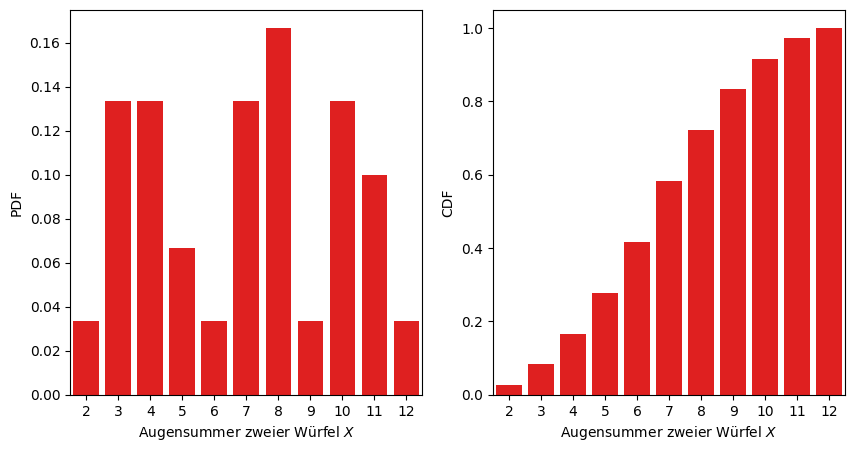

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.barplot(data=dataWürfel_empirisch, x="Summe Augenzahl", y="Rel. Häufigkeiten", color="r", ax=axes[0]) # PDF
axes[0].set_xlabel('Augensummer zweier Würfel $X$')
axes[0].set_ylabel('PDF')

sns.barplot(data=dataWürfel_empirisch, x="Summe Augenzahl", y="CDF", color="r", ax=axes[1]) # CDF
axes[1].set_xlabel('Augensummer zweier Würfel $X$')
axes[1].set_ylabel('CDF');

Bestimme $P(X = 7)$, $P(X \leq 7)$, $P(X > 7 )$ und $P( 3\leq X < 7 )$:

In [13]:
dataWürfel_empirisch["Rel. Häufigkeiten"].values[dataWürfel_empirisch["Summe Augenzahl"].values == 7][0]

0.13333333333333333

In [14]:
dataWürfel_empirisch["CDF"].values[dataWürfel_empirisch["Summe Augenzahl"].values == 7][0]

0.5833333333333334

In [15]:
1 - dataWürfel_empirisch["CDF"].values[dataWürfel_empirisch["Summe Augenzahl"].values == 7][0]

0.41666666666666663

In [16]:
dataWürfel_empirisch["CDF"].values[dataWürfel_empirisch["Summe Augenzahl"].values == 6][0] - dataWürfel_empirisch["CDF"].values[dataWürfel_empirisch["Summe Augenzahl"].values == 2][0]

0.3888888888888889

Text(0, 0.5, 'PDF')

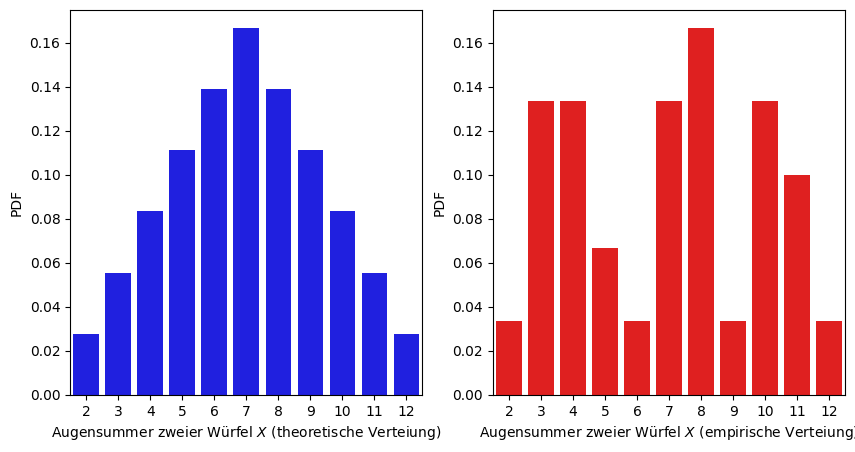

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.barplot(data=dataWürfel, x="Summe Augenzahl", y="Rel. Häufigkeiten", color="b", ax=axes[0]) # PDF
axes[0].set_xlabel('Augensummer zweier Würfel $X$ (theoretische Verteiung)')
axes[0].set_ylabel('PDF')

sns.barplot(data=dataWürfel_empirisch, x="Summe Augenzahl", y="Rel. Häufigkeiten", color="r", ax=axes[1]) # PDF
axes[1].set_xlabel('Augensummer zweier Würfel $X$ (empirische Verteiung)')
axes[1].set_ylabel('PDF')